In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('../../src/zero_to_hero/part_02_makemore/names.txt', 'r').read().splitlines()

In [3]:
len(words)

32033

In [4]:
# We had S/E special tokens, but now just "."
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [5]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [6]:
import numpy as np
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

# Why does he not apply Kaiming to W2?
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * 5/3 / np.sqrt(n_embd * block_size) # tanh saturation step, Kaiming
b1 = torch.randn(n_hidden,                        generator=g) * 0.01 # tanh saturation step, helps to break symmetry
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 5/3 / np.sqrt(n_hidden) # Initialise step 1
b2 = torch.randn(vocab_size,                      generator=g) * 0.0 # initialise step 2

# BatchNorm parameters
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b1, b2, bngain, bnbias]
#parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

12297


In [7]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  # Linear layer
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  hpreact = bngain * (hpreact - hpreact.mean(axis=0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
  # Non-linearity
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())


      0/ 200000: 3.9446
  10000/ 200000: 2.1725
  20000/ 200000: 2.4099
  30000/ 200000: 2.4611
  40000/ 200000: 1.9828
  50000/ 200000: 2.3634
  60000/ 200000: 2.4155
  70000/ 200000: 1.9953
  80000/ 200000: 2.3992
  90000/ 200000: 2.1629
 100000/ 200000: 1.9657
 110000/ 200000: 2.3053
 120000/ 200000: 2.0005
 130000/ 200000: 2.4404
 140000/ 200000: 2.2785
 150000/ 200000: 2.1575
 160000/ 200000: 1.9269
 170000/ 200000: 1.8066
 180000/ 200000: 2.0369
 190000/ 200000: 1.9236


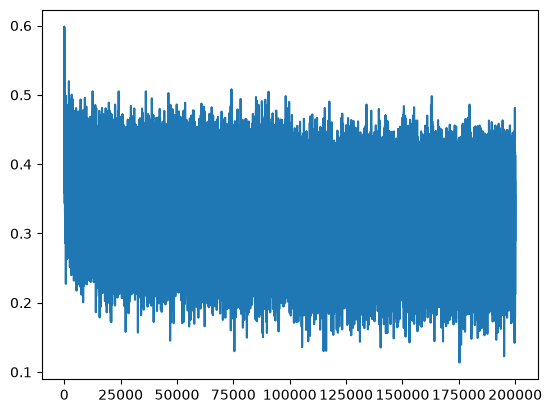

In [9]:
plt.plot(lossi)

In [10]:
# calibrate the batch norm at the end of training
# papers answer to how do we look at examples at the end of training?
# as now the NN assumes we have batches when inputting

with torch.no_grad():
  # pass the training set through
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  # measure the mean/std over the entire training set
  bnmean = hpreact.mean(0, keepdim=True)
  bnstd = hpreact.std(0, keepdim=True)

In [11]:
# this decorator disables gradient tracking - if we won't ever call loss.backward, more efficient
@torch.no_grad() 
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1  + b1
  hpreact = bngain * (hpreact - hpreact.mean(axis=0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.07157039642334
val 2.1083459854125977


In [14]:
## Another possible way - estiamte bnmean, bnstd in a EMA way
import numpy as np
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

# Why does he not apply Kaiming to W2?
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * 5/3 / np.sqrt(n_embd * block_size) # tanh saturation step, Kaiming
b1 = torch.randn(n_hidden,                        generator=g) * 0.01 # tanh saturation step, helps to break symmetry
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 5/3 / np.sqrt(n_hidden) # Initialise step 1
b2 = torch.randn(vocab_size,                      generator=g) * 0.0 # initialise step 2

# BatchNorm parameters
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b1, b2, bngain, bnbias]
#parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

12297


In [15]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  # Linear layer
  hpreact = embcat @ W1 + b1 # hidden layer pre-activation
  # Batch norm
  bnmean = hpreact.mean(axis=0, keepdim=True)
  bnstd = hpreact.std(axis=0, keepdim=True)
  hpreact = bngain * (hpreact - bnmean) / bnstd + bnbias
  with torch.no_grad():
      bnmean_running = 0.999 * bnmean_running + 0.001 * bnmean
      bnstd_running = 0.999 * bnstd_running + 0.001 * bnstd
  # Non-linearity
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())


      0/ 200000: 3.9446
  10000/ 200000: 2.1725
  20000/ 200000: 2.4099
  30000/ 200000: 2.4611
  40000/ 200000: 1.9828
  50000/ 200000: 2.3634
  60000/ 200000: 2.4155
  70000/ 200000: 1.9953
  80000/ 200000: 2.3992
  90000/ 200000: 2.1629
 100000/ 200000: 1.9657
 110000/ 200000: 2.3053
 120000/ 200000: 2.0005
 130000/ 200000: 2.4404
 140000/ 200000: 2.2785
 150000/ 200000: 2.1575
 160000/ 200000: 1.9269
 170000/ 200000: 1.8066
 180000/ 200000: 2.0369
 190000/ 200000: 1.9236


In [16]:
# can verify bnmean and bnmean_running are similar

with torch.no_grad():
  # pass the training set through
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  # measure the mean/std over the entire training set
  bnmean = hpreact.mean(0, keepdim=True)
  bnstd = hpreact.std(0, keepdim=True)

# check!

In [17]:
@torch.no_grad() 
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1  + b1
  hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0713062286376953
val 2.1085898876190186


In [18]:
# Losses are basically the same! And we are implementing in a rolling way, no expensive computation

In [19]:
# two other points
# We normally scale by sqrt(variance + epsilon) for some epsilon, instead of just std -> prevents numerical badness when variance is close to zero
# Now note the bias b1 is useless - b1 just absorbed by bnmean
b1.grad

tensor([-9.3132e-10, -9.3132e-10, -1.8626e-09,  1.3970e-09, -4.6566e-10,
        -1.8626e-09,  4.6566e-10, -1.8626e-09,  0.0000e+00,  9.3132e-10,
        -1.3970e-09, -1.8626e-09,  9.3132e-10, -2.7940e-09,  0.0000e+00,
         3.7253e-09,  1.3970e-09,  5.5879e-09,  1.0477e-09,  1.8626e-09,
        -1.3970e-09, -9.3132e-10, -2.3283e-10, -1.8626e-09,  0.0000e+00,
         6.4028e-10,  1.8626e-09,  3.7253e-09, -4.6566e-10, -5.8208e-10,
         1.8626e-09,  0.0000e+00,  0.0000e+00,  1.6298e-09,  4.5475e-13,
         1.8626e-09, -4.6566e-10, -9.3132e-10, -3.0268e-09, -9.3132e-10,
         9.3132e-10,  1.1642e-09, -9.3132e-10, -9.3132e-10,  4.6566e-10,
        -2.3283e-10, -3.4925e-10, -2.3283e-09,  5.8208e-11,  0.0000e+00,
        -3.7253e-09,  1.8626e-09, -2.3283e-10,  2.7940e-09, -9.3132e-10,
         4.6566e-10,  0.0000e+00, -4.6566e-10, -6.9849e-10,  3.4925e-09,
         9.3132e-10, -9.3132e-10,  7.5670e-10, -1.0477e-09,  0.0000e+00,
         4.6566e-10, -5.8208e-10,  5.8208e-11,  0.0

In [20]:
# Lets remove
import numpy as np
# MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

# Why does he not apply Kaiming to W2?
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C  = torch.randn((vocab_size, n_embd),            generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * 5/3 / np.sqrt(n_embd * block_size) # tanh saturation step, Kaiming
#b1 = torch.randn(n_hidden,                        generator=g) * 0.01 # tanh saturation step, helps to break symmetry
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 5/3 / np.sqrt(n_hidden) # Initialise step 1
b2 = torch.randn(vocab_size,                      generator=g) * 0.0 # initialise step 2

# BatchNorm parameters
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b2, bngain, bnbias]
#parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

12097


In [21]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
  # Linear layer
  hpreact = embcat @ W1 #+ b1 # hidden layer pre-activation
  # Batch norm
  bnmean = hpreact.mean(axis=0, keepdim=True)
  bnstd = hpreact.std(axis=0, keepdim=True)
  hpreact = bngain * (hpreact - bnmean) / bnstd + bnbias
  with torch.no_grad():
      bnmean_running = 0.999 * bnmean_running + 0.001 * bnmean
      bnstd_running = 0.999 * bnstd_running + 0.001 * bnstd
  # Non-linearity
  h = torch.tanh(hpreact) # hidden layer
  logits = h @ W2 + b2 # output layer
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())


      0/ 200000: 4.1357
  10000/ 200000: 2.0278
  20000/ 200000: 2.6558
  30000/ 200000: 2.0230
  40000/ 200000: 2.2787
  50000/ 200000: 1.8606
  60000/ 200000: 2.0680
  70000/ 200000: 2.3552
  80000/ 200000: 2.3466
  90000/ 200000: 2.1315
 100000/ 200000: 2.3130
 110000/ 200000: 2.2493
 120000/ 200000: 1.6537
 130000/ 200000: 1.9163
 140000/ 200000: 2.2877
 150000/ 200000: 1.9321
 160000/ 200000: 2.0254
 170000/ 200000: 2.3684
 180000/ 200000: 2.0840
 190000/ 200000: 2.0807


In [22]:
# Usually BN is put after layers with multiplication (linear, convolutional)
# params (gain) are trained with backpropagation
# Whole estimates just maintain ema